# PSD Basics

---
## Processing EDFs Using Openseize

You can:
1. Read in the desired 5000 Hz time segments and downsample each segment individually
2. Downsample entire EDF file and work from downsampled files (can send downsampling code)

#### 5000 Hz File

In [1]:
from pathlib import Path

from openseize import producer
from openseize.file_io import edf
from openseize.resampling import resampling
from openseize.spectra.estimators import psd

In [2]:
# 5000 Hz File
# ── Edit Path ──────────────────────────────────────────────────────────────
EDF_PATH = Path("/media/matt/Data_A/leah/GUI_Test3/ASR05_P106_91_29_ASO p3wks_2 days EEG_2022-03-02_10_23_55.edf")
FS = 5000

START_SEC = 4.5
STOP_SEC = 20.1

M = 20 #Factor to downsample by: 5000 Hz / 20 = 250 Hz
fs_downsampled = FS / 20

Using Producer (better for longer segments): 

In [3]:
with edf.Reader(EDF_PATH) as reader:
    reader.channels = [0,1,2]
    pro = producer(reader, chunksize=(30e5), start= int(START_SEC * FS), stop=int(STOP_SEC * FS), axis=-1)
    downsample_pro = resampling.downsample(pro, M=M, fs=FS, chunksize=(30e5), axis=-1)

    cnt, freqs, psds_raw = psd(downsample_pro, fs=fs_downsampled, resolution=0.5, window='hann', overlap=0.5)

print(f"Frequency bins : {len(freqs)}  ({freqs[0]:.1f} – {freqs[-1]:.1f} Hz)")
print(f"PSD shape      : {psds_raw.shape}  (channels × freqs)")
print(f"Window count   : {cnt}")

Frequency bins : 251  (0.0 – 125.0 Hz)
PSD shape      : (3, 251)  (channels × freqs)
Window count   : 14


Using Array:

In [4]:
with edf.Reader(EDF_PATH) as reader:
    reader.channels = [0,1,2]
    data = reader.read(start=int(START_SEC*FS), stop=int(STOP_SEC*FS))
    downsample_data = resampling.downsample(data, M=M, fs=FS, chunksize=(30e5), axis=-1)

    cnt, freqs, psds_raw = psd(downsample_data, fs=fs_downsampled, resolution=0.5, window='hann', overlap=0.5)

print(f"Frequency bins : {len(freqs)}  ({freqs[0]:.1f} – {freqs[-1]:.1f} Hz)")
print(f"PSD shape      : {psds_raw.shape}  (channels × freqs)")
print(f"Window count   : {cnt}")

Frequency bins : 251  (0.0 – 125.0 Hz)
PSD shape      : (3, 251)  (channels × freqs)
Window count   : 14


#### 250 Hz File (Already Downsampled)

In [5]:
EDF_PATH = Path("/media/matt/Data_A/leah/GUI_Test3/standard/ASR05_P106_91_29_ASO p3wks_2 days EEG_2022-03-02_10_23_55_PREPROCESSED.edf")

FS = 250

START_SEC = 4.5
STOP_SEC = 20.1


with edf.Reader(EDF_PATH) as reader:
    print("Shape (channels × samples):", reader.shape)
    print("Channels                  :", reader.header.names)
    print("Samples per record        :", reader.header.samples_per_record)
    print("Duration                  :", reader.shape[-1] / FS / 3600, "hours")
    
    # Load first 30 seconds for inspection
    reader.channels = [0, 1, 2]  # skip EMG for plotting
    data = reader.read(start=int(START_SEC*FS), stop=(STOP_SEC * FS))

cnt, freqs, psds_raw = psd(data, fs=FS, resolution=0.5, window='hann', overlap=0.5)


Shape (channels × samples): (4, np.int64(5400000))
Channels                  : ['EEG EEG_1_SA-B', 'EEG EEG_2_SA-B', 'EEG EEG_3_SA-B', 'EEG EEG_4_SA-B']
Samples per record        : [250, 250, 250, 250]
Duration                  : 6.0 hours


---
## Processing Any Data Array Using Scipy

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

Example uses randomly generated signal -> Can be signal read in from anywhere

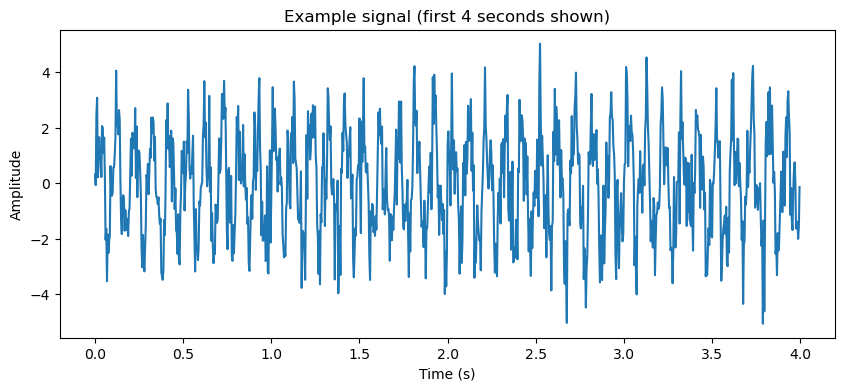

In [7]:
fs = 250  # sampling frequency in Hz
duration = 10  # seconds
t = np.arange(0, duration, 1/fs)

rng = np.random.default_rng(42)

sig_10hz = 2.0 * np.sin(2 * np.pi * 10 * t)
sig_25hz = 0.8 * np.sin(2 * np.pi * 25 * t)
noise = 1.0 * rng.normal(size=len(t))

x = sig_10hz + sig_25hz + noise

plt.figure(figsize=(10, 4))
plt.plot(t[:1000], x[:1000])
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.title('Example signal (first 4 seconds shown)')
plt.show()

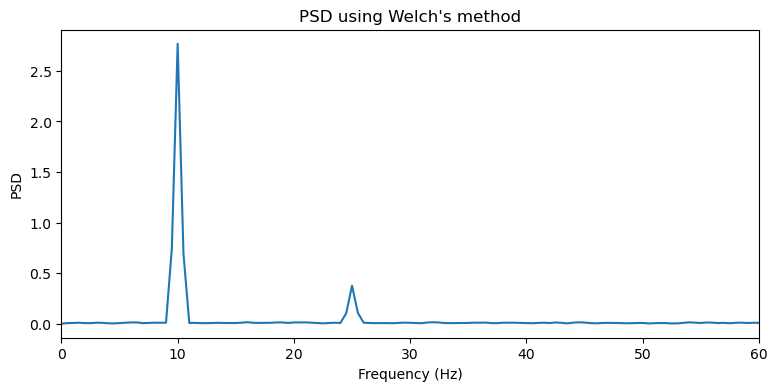

In [8]:
freqs, psd = signal.welch(
    x,
    fs=fs,
    nperseg=500,      # 2-second windows at 250 Hz
    noverlap=250,    # 50% overlap
    scaling='density'
)

plt.figure(figsize=(9, 4))
plt.plot(freqs, psd)
plt.xlim(0, 60)
plt.xlabel('Frequency (Hz)')
plt.ylabel('PSD')
plt.title("PSD using Welch's method")
plt.show()

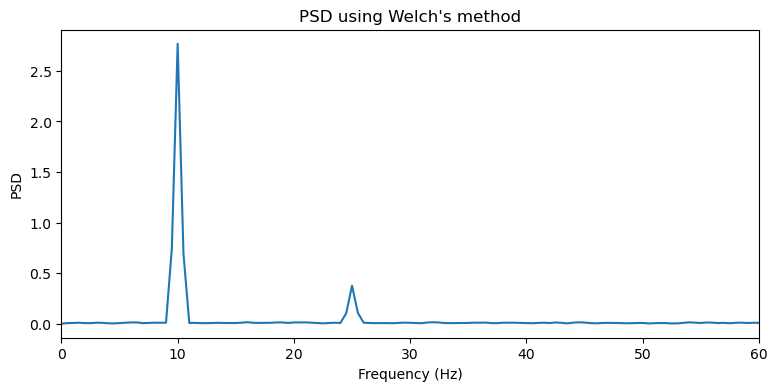

In [9]:
plt.figure(figsize=(9, 4))
plt.plot(freqs, psd)
plt.xlim(0, 60)
plt.xlabel('Frequency (Hz)')
plt.ylabel('PSD')
plt.title("PSD using Welch's method")
plt.show()